<div class="alert alert-block alert-info">
<h2>AI bruk</h2>

Jeg har brukt Claude som støtte gjennom arbeidet med denne innleveringen.

- **Feilsøking og feilmeldinger:** Claude hjalp meg med å tolke feilmeldinger og finne årsaker, blant annet at pyproj ikke fantes ferdigbygget for Intel-Mac med macOS 12 (løst med `--only-binary=:all:`), en tegnkodingsfeil der «RØ» ble lest feil fra shapefilen, at pakker ble installert i Anaconda-miljøet i stedet for prosjektmiljøet, og en feilet `git push` (HTTP 400).
- **Veiledning i verktøyene:** hjelp med å finne riktige kartlag i NVE Atlas og eksportere dem som shapefiler, med Git (ny branch, `.gitignore`) og med VS Code og virtuelle miljøer.
- **Nedlasting av værdata:** Claude foreslo å runde de tilfeldige punktene til ERA5-rutenettet og vekte gjennomsnittet etter antall punkter per rute, slik at nedlastingen holdt seg innenfor API-grensene til open-meteo.
- **Formulering:** Claude hjalp meg med kildelisten og med formuleringer i loggen og tolkningene.

</div>

<div class="alert alert-block alert-success">
<h2>Logg</h2>

Jeg startet med å lage en ny branch (del3) og rette opp tilbakemeldingen fra peer review: tabellsiden fikk en månedsvelger, slik at minigrafene ikke lenger er låst til januar 1995. Samtidig rettet jeg overlappende datoetiketter og et kakediagram som byttet størrelse på kraftflytsiden.

Det var vanskeligere enn forventet å finne shapefilene i NVE Atlas. Søkefeltet søker etter steder, ikke kartlag, så jeg måtte lete gjennom lagoversikten. Elspotområdene lå under *Nettanlegg → Nettområder → Budområder*, og nedbørområdene var NVE sine regioner under *Administrasjon*. Begge ble eksportert som shapefiler fra tabellvisningen. De fem regionene slo jeg sammen til de tre VASS-områdene i Magasinstatistikk etter hintet i oppgaven. Her oppdaget jeg en tegnkodingsfeil: «RØ» ble lest som rare tegn, slik at Region Øst manglet, før jeg leste filen med UTF-8. Deretter trakk jeg 1000 tilfeldige punkter i hver region.

Den største utfordringen var nedlastingen fra open-meteo. 1000 punkter for et helt år ville tilsvart rundt 26 000 API-kall, mens gratisgrensen er 10 000 per døgn. Fordi ERA5 har et rutenett på 0,25°, havner mange punkter i samme rute. Jeg hentet derfor hver rute bare én gang og vektet gjennomsnittet etter antall punkter, noe som gir det samme resultatet. For NO3 ble det 298 ruter, og nedlastingen tok likevel nesten en time på grunn av timegrensen.

Med SPC-analysen av nedbøren ble 7,4 % av timene outliers, alle over den øvre grensen. Det skyldes at nedbør er skjevfordelt, med mange tørre timer og noen få med kraftig regn. LOF på temperaturen fant derimot ikke de varmeste eller kaldeste timene, men brå endringer sammenlignet med timene rundt. STL og spektrogrammet av fyllingsgraden viste en tydelig og stabil årssyklus.

I Streamlit-appen la jeg til en felles områdevelger i sidemenyen, som huskes mellom sidene og styrer hvilke værdata som lastes ned. Jeg laget to nye sider med faner: én for STL og spektrogram, og én for SPC og LOF. Fordi en full nedlasting tar for lang tid i en app, bruker appen 10 tilfeldige ERA5-ruter per område, mens den komplette filen fra notebooken brukes for NO3 2024. Analysefunksjonene ligger i en egen modul, slik at notebooken og appen bruker den samme koden. Placeholder-siden ble fjernet, og sidene ble ordnet etter magasindata, værdata og kraftflyt.

Underveis fikk jeg også problemer med installasjon av pakker på min eldre Mac, og jeg lærte å sjekke at riktig miljø er aktivert før jeg installerer noe.

</div>

<div class="alert alert-block alert-warning">
<h2>Kilder</h2>

**Data og kart**
- **Shapefiler for budområder og NVE-regioner:** eksportert fra kartlagene i NVE Atlas, brukt til å trekke tilfeldige punkter per område. Kilde: atlas.nve.no
- **Værdata (ERA5):** timesdata for temperatur, nedbør med mer, hentet fra open-meteo sitt historiske API. Kilde: open-meteo.com/en/docs/historical-weather-api
- **API-grenser hos open-meteo:** brukt for å forstå hvordan kall telles og hvorfor nedlastingen måtte begrenses. Kilde: open-meteo.com/en/pricing og bloggposten *Weather Data for Multiple Locations At Once*
- **Magasinstatistikk:** fyllingsgrad hentet fra NVE sitt API, som i del 2.

**Analyser**
- **SPC, robust statistikk og DCT-filtrering:** inspirert av kursnotebooken *Outlier statistics* (2_Outlier_statistics.ipynb).
- **Local Outlier Factor:** inspirert av kursnotebooken *Anomaly detection* (3_Anomaly_detection.ipynb) og scikit-learn-dokumentasjonen for LocalOutlierFactor.
- **STL:** inspirert av kursnotebooken *Decomposition* (3_Decomposition.ipynb) og statsmodels-dokumentasjonen for STL.
- **Spektrogram:** inspirert av kursnotebooken *Spectrograms* (5_Spectrograms.ipynb) og SciPy-dokumentasjonen for `scipy.signal.stft`.
- **Geodata i Python:** geopandas-dokumentasjonen for `read_file`, `dissolve` og `sample_points`.

**Streamlit-appen**
- **st.tabs, st.metric, st.session_state og st.cache_data:** brukt til de nye sidene og den felles områdevelgeren. Kilde: Streamlit API-referanse

</div>

In [2]:
# Read the two shapefiles exported from NVE Atlas:
#  - Budområder (Nettanlegg > Nettområder): the electricity price areas NO1-NO5
#  - NVE_Region (Administrasjon > Administrative områder): NVE's five regions,
#    which are merged below to match the precipitation areas (VASS) in Magasinstatistikk
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SHAPE_DIR = Path('../project_data/shapefiles')

# geopandas can read a zipped shapefile directly
elspot = gpd.read_file(f"zip://{SHAPE_DIR / 'budomrader.zip'}")
regions = gpd.read_file(f"zip://{SHAPE_DIR / 'nve_region.zip'}", encoding='utf-8')

for name, gdf in [('Budområder', elspot), ('NVE_Region', regions)]:
    print(f'--- {name} ---')
    print('CRS:', gdf.crs)                         # expected UTM33 (EPSG:25833), i.e. metres
    print(gdf.drop(columns='geometry').iloc[:, :3])

--- Budområder ---
CRS: EPSG:25833
   objectid budomr  globalid
0       1.0   NO 1       NaN
1       2.0   NO 2       NaN
2       3.0   NO 3       NaN
3       4.0   NO 4       NaN
4       5.0   NO 5       NaN
--- NVE_Region ---
CRS: EPSG:25833
   OBJECTID REGION         REGIONNAVN
0       1.0     RV        Region Vest
1       2.0     RM  Region Midt-Norge
2       3.0     RN        Region Nord
3       4.0     RØ         Region Øst
4       5.0     RS         Region Sør


## Matching the regions to Magasinstatistikk
Magasinstatistikk has the electricity areas EL 1-5, three precipitation areas VASS 1-3 and Norway as a whole (NO 0). Following the task's hint, NVE's regions are merged as: VASS 1 (East) = RØ + RS, VASS 2 (West) = RV, VASS 3 (North) = RM + RN.

Unmatched regions: []
     area
0    EL 1
1    EL 2
2    EL 3
3    EL 4
4    EL 5
5  VASS 1
6  VASS 2
7  VASS 3
8    NO 0


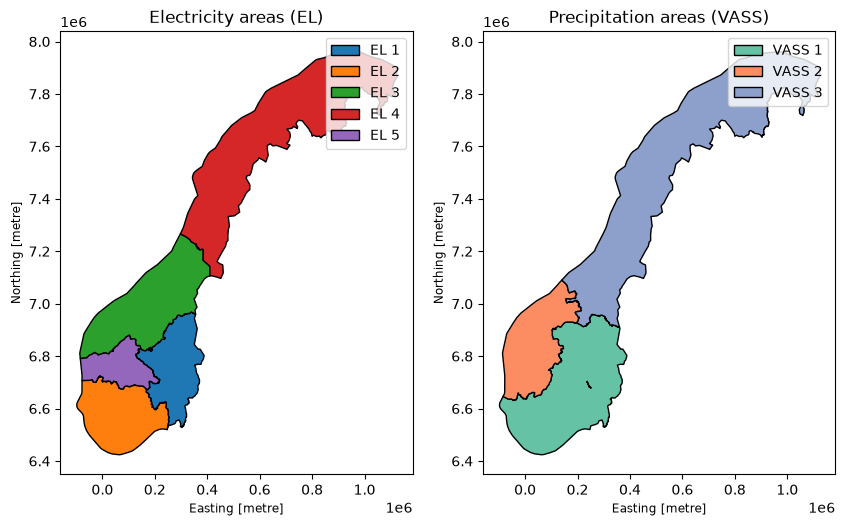

In [3]:
# Build one table of regions with the same labels as the Magasinstatistikk data
# ('EL 1'...'EL 5', 'VASS 1'...'VASS 3', 'NO 0'), so the weather data can later be
# matched with the area selector in the app.

# Electricity areas: 'NO 1' -> 'EL 1'
el = elspot[['budomr', 'geometry']].copy()
el['area'] = el['budomr'].str.replace('NO', 'EL')

# Precipitation areas: merge NVE regions per the task's hint
# (East = RS + RØ, North = RM + RN, West = RV)
vass_map = {'RØ': 'VASS 1', 'RS': 'VASS 1',
            'RV': 'VASS 2',
            'RM': 'VASS 3', 'RN': 'VASS 3'}
regions['area'] = regions['REGION'].map(vass_map)
print('Unmatched regions:', regions.loc[regions['area'].isna(), 'REGION'].tolist())  # should be []
vass = regions.dissolve(by='area').reset_index()[['area', 'geometry']]   # merge polygons

# Norway as a whole ('NO 0'): the union of all electricity areas
no0 = gpd.GeoDataFrame({'area': ['NO 0']}, geometry=[el.union_all()], crs=el.crs)

areas = pd.concat([el[['area', 'geometry']], vass, no0], ignore_index=True)
areas = gpd.GeoDataFrame(areas, crs=el.crs)
print(areas[['area']])

# Plot to check that the regions look right
fig, axes = plt.subplots(1, 2, figsize=(10, 7))
areas[areas['area'].str.startswith('EL')].plot(ax=axes[0], column='area', legend=True,
                                                cmap='tab10', edgecolor='black')
axes[0].set_title('Electricity areas (EL)')
areas[areas['area'].str.startswith('VASS')].plot(ax=axes[1], column='area', legend=True,
                                                  cmap='Set2', edgecolor='black')
axes[1].set_title('Precipitation areas (VASS)')
plt.show()

## Random locations per region
1000 random locations are sampled inside each region, to be used for the weather data download.

area
EL 1      1000
EL 2      1000
EL 3      1000
EL 4      1000
EL 5      1000
NO 0      1000
VASS 1    1000
VASS 2    1000
VASS 3    1000
dtype: int64


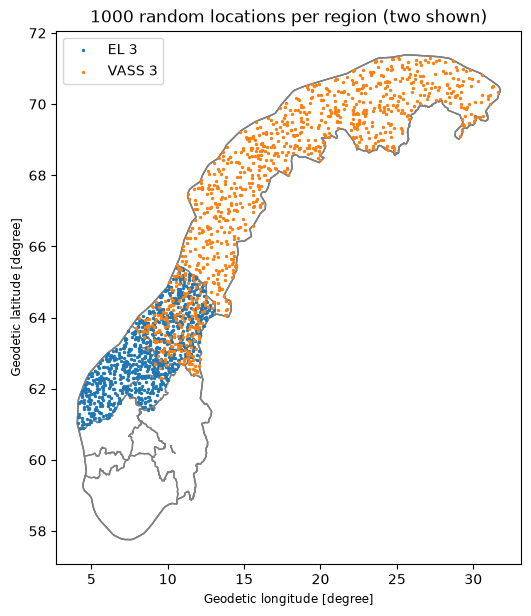

In [4]:
# Randomly sample 1000 locations inside each region.
# Sampling is done in UTM33 (metres, roughly equal-area), so the points are evenly spread
# over the area. A fixed seed makes the sample reproducible. Afterwards the points are
# converted to longitude/latitude (WGS84), which is what open-meteo expects.
N_POINTS = 1000
SEED = 320

rows = []
for i, row in areas.iterrows():
    pts = gpd.GeoSeries([row.geometry], crs=areas.crs).sample_points(N_POINTS, rng=SEED + i)
    pts = pts.explode(index_parts=False).to_crs(epsg=4326)   # MultiPoint -> points, -> lon/lat
    rows.append(pd.DataFrame({'area': row['area'], 'lon': pts.x.values, 'lat': pts.y.values}))

locations = pd.concat(rows, ignore_index=True)
print(locations.groupby('area').size())        # 1000 per area

# Save the locations so the Streamlit app can use the same points without the shapefiles
locations.to_csv('../project_data/locations.csv', index=False)

# Check visually: points for NO3 and VASS 3
ax = areas.to_crs(epsg=4326).plot(color='none', edgecolor='grey', figsize=(6, 8))
for a, c in [('EL 3', 'tab:blue'), ('VASS 3', 'tab:orange')]:
    sub = locations[locations['area'] == a]
    ax.scatter(sub['lon'], sub['lat'], s=2, color=c, label=a)
ax.legend()
ax.set_title('1000 random locations per region (two shown)')
plt.show()

## Weather data from open-meteo (ERA5)
Hourly historical reanalysis data (ERA5) is downloaded from open-meteo's archive API for the 1000 random locations in a region. ERA5 has a 0.25° grid, so many of the 1000 locations fall in the same grid cell and would return identical data. Each grid cell is therefore downloaded only once, and the regional average is weighted by the number of locations in each cell. This gives exactly the same average as using all 1000 locations, while staying within open-meteo's free API limits (600 calls/minute, 5000/hour, 10 000/day, where a request counts as roughly *locations × days / 14* calls).

In [5]:
# Download hourly ERA5 data from open-meteo for a region and a time interval
import time
import requests
import pandas as pd
from pathlib import Path

ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
HOURLY_VARS = ['temperature_2m', 'precipitation', 'rain', 'snowfall',
               'relative_humidity_2m', 'wind_speed_10m', 'cloud_cover', 'shortwave_radiation']


def download_weather(area, start, end, locations=locations, variables=HOURLY_VARS, batch_size=20):
    """
    Download hourly ERA5 data for a region ('EL 3', 'VASS 1', ...) between start and end
    ('YYYY-MM-DD') and return the average over the region's random locations.
    """
    # Saved file from an earlier download is read instead of downloading again
    file = Path(f"../project_data/weather_{area.replace(' ', '')}_{start}_{end}.csv")
    if file.exists():
        return pd.read_csv(file, index_col='time', parse_dates=True)

    # Round the locations to the ERA5 0.25° grid and count the locations per grid cell
    pts = locations[locations['area'] == area]
    cells = (pts.assign(lat=(pts['lat'] * 4).round() / 4, lon=(pts['lon'] * 4).round() / 4)
                .groupby(['lat', 'lon']).size().rename('n').reset_index())
    print(f"{area}: {len(pts)} locations in {len(cells)} unique grid cells")

    frames = []
    for i in range(0, len(cells), batch_size):
        batch = cells.iloc[i:i + batch_size]
        params = {'latitude': ','.join(batch['lat'].astype(str)),
                  'longitude': ','.join(batch['lon'].astype(str)),
                  'start_date': start, 'end_date': end,
                  'hourly': ','.join(variables), 'models': 'era5', 'timezone': 'GMT'}

        # Request the batch; wait 5 minutes and try again when the API rate limit is reached
        r = requests.get(ARCHIVE_URL, params=params, timeout=300)
        while r.status_code == 429:
            print("  Rate limit reached, waiting 5 min ...", flush=True)
            time.sleep(300)
            r = requests.get(ARCHIVE_URL, params=params, timeout=300)
        r.raise_for_status()

        # One DataFrame per grid cell, with the number of locations in the cell as weight
        for n, loc in zip(batch['n'], r.json()):
            df = pd.DataFrame(loc['hourly'])
            df['n'] = n
            frames.append(df)
        print(f"  {min(i + batch_size, len(cells))}/{len(cells)} cells downloaded", flush=True)
        time.sleep(61)

    # Weighted average over the grid cells = average over all the region's locations
    data = pd.concat(frames)
    data['time'] = pd.to_datetime(data['time'])
    weather = (data[variables].multiply(data['n'], axis=0).groupby(data['time']).sum()
               .div(data.groupby('time')['n'].sum(), axis=0))
    weather.to_csv(file)
    return weather

In [6]:
# Download hourly data for NO3 (EL 3) for 2024
weather_no3 = download_weather('EL 3', '2024-01-01', '2024-12-31')
print(weather_no3.shape)
weather_no3.describe().round(2)

(8784, 8)


,temperature_2m,precipitation,rain,snowfall,relative_humidity_2m,wind_speed_10m,cloud_cover,shortwave_radiation
count,8784.00,8784.00,8784.00,8784.00,8784.00,8784.00,8784.00,8784.00
mean,5.80,0.20,0.17,0.02,78.98,14.91,76.84,99.86
std,6.62,0.27,0.24,0.05,8.90,5.89,22.30,158.49
min,-11.31,0.00,0.00,0.00,44.00,3.64,1.53,0.00
25%,1.32,0.02,0.01,0.00,74.07,10.47,64.76,0.00
50%,5.44,0.10,0.07,0.00,80.75,13.77,83.33,4.29
75%,11.06,0.29,0.24,0.02,85.40,18.40,95.21,153.38
max,22.26,2.67,2.03,0.90,95.88,46.09,100.00,743.03


## Outliers and anomalies

### Precipitation: Statistical Process Control (SPC) on seasonally adjusted variations
The precipitation series is high-pass filtered with the Discrete Cosine Transform (DCT): the lowest-frequency DCT coefficients (the slow, seasonal variation) are set to zero and the series is transformed back. The result is the seasonally adjusted variation (called SATV in the task; here it is computed from precipitation, as the task text says). Robust statistics (median and median absolute deviation, MAD) of the SATV over the whole year give the SPC limits. The limits are drawn around the seasonal level of the original series, and values outside are marked as outliers.

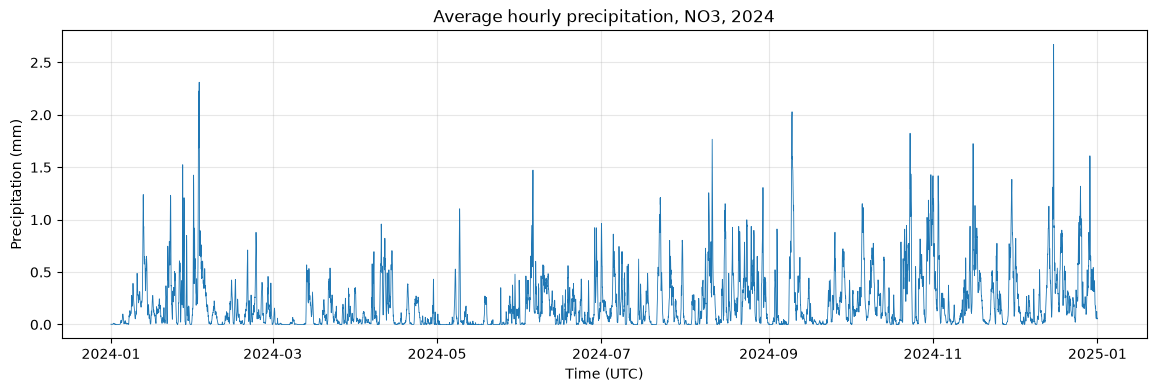

In [7]:
# Plot the average precipitation in NO3 as a function of time
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(weather_no3.index, weather_no3['precipitation'], linewidth=0.6)
ax.set_title('Average hourly precipitation, NO3, 2024')
ax.set_xlabel('Time (UTC)')
ax.set_ylabel('Precipitation (mm)')
ax.grid(alpha=0.3)
plt.show()

In [10]:
from scipy.fft import dct, idct
from scipy.stats import median_abs_deviation


def spc_outliers(series, cutoff=25, n_std=3):
    """
    Find outliers in a time series with Statistical Process Control (SPC) on the
    DCT high-pass filtered values (SATV).

    cutoff : DCT frequency cut-off; the 'cutoff' lowest frequencies are removed
             (25 removes variations slower than about a month in one year of hourly data)
    n_std  : number of robust standard deviations between the median and the SPC limits
    Returns the plot, a summary and the outlying values.
    """
    values = series.values

    # High-pass filter: set the lowest DCT frequencies to zero and transform back
    freq = dct(values, norm='ortho')
    freq[:cutoff] = 0
    satv = idct(freq, norm='ortho')

    # Robust statistics of the SATV for the whole year: median and MAD scaled to a standard deviation
    median = np.median(satv)
    sd = median_abs_deviation(satv, scale='normal')

    # SPC limits: the removed slow variation plus median ± n_std robust standard deviations
    slow = values - satv
    upper = slow + median + n_std * sd
    lower = slow + median - n_std * sd
    is_outlier = (values > upper) | (values < lower)

    # Plot the series and the SPC limits, with the outliers in red
    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(series.index, values, linewidth=0.6, label=series.name)
    ax.plot(series.index, upper, 'k--', linewidth=1, label=f'SPC limits (± {n_std} robust SD)')
    ax.plot(series.index, lower, 'k--', linewidth=1)
    ax.scatter(series.index[is_outlier], values[is_outlier], color='red', s=10, zorder=3, label='Outliers')
    ax.set_title(f'SPC outliers in {series.name} (DCT cut-off {cutoff}, {n_std} SD)')
    ax.set_xlabel('Time (UTC)')
    ax.set_ylabel(series.name)
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right')

    # Summary of the outliers
    outliers = series[is_outlier]
    summary = {
        'number of outliers': len(outliers),
        'share of outliers (%)': round(100 * len(outliers) / len(series), 2),
        'above upper limit': int((values > upper).sum()),
        'below lower limit': int((values < lower).sum()),
        'robust SD': round(float(sd), 3),
    }
    return fig, summary, outliers

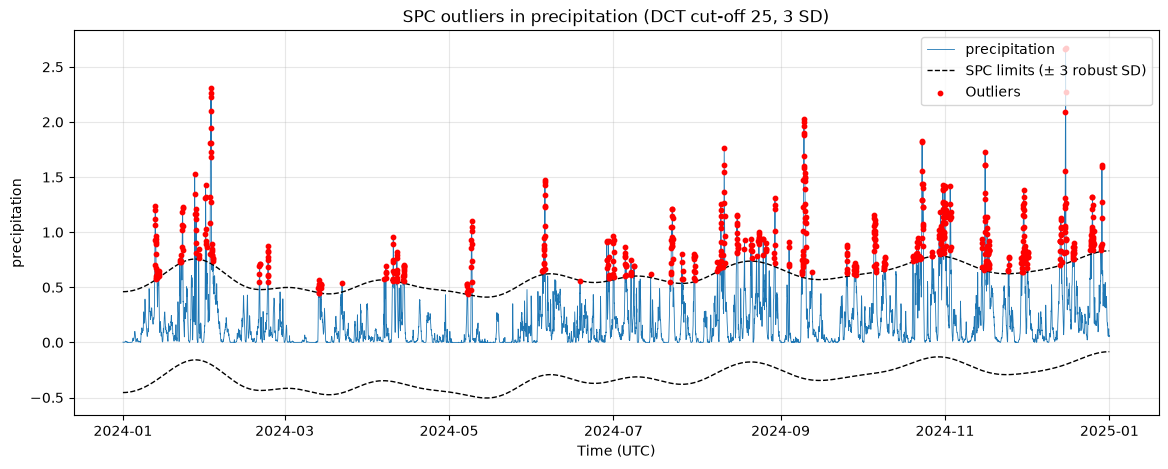

{'number of outliers': 653, 'share of outliers (%)': 7.43, 'above upper limit': 653, 'below lower limit': 0, 'robust SD': 0.153}


time
2024-12-15 18:00:00    2.6712
2024-12-15 17:00:00    2.6637
2024-02-02 18:00:00    2.3112
2024-12-15 19:00:00    2.2676
2024-02-02 17:00:00    2.2670
2024-02-02 12:00:00    2.2262
2024-02-02 13:00:00    2.0967
2024-12-15 16:00:00    2.0882
2024-09-09 17:00:00    2.0290
2024-09-09 16:00:00    1.9976
Name: precipitation, dtype: float64

In [12]:
import numpy as np
from scipy.fft import dct, idct
from scipy.stats import median_abs_deviation
# Test the function on the precipitation in NO3 with the default parameters
fig, summary, outliers = spc_outliers(weather_no3['precipitation'])
plt.show()
print(summary)
outliers.sort_values(ascending=False).head(10)     # the 10 largest outliers

**Interpretation:** With the default parameters (DCT cut-off 25, i.e. variations slower than about a month removed, and ±3 robust SD), 7.4 % of the hours are marked as outliers, all above the upper limit. The lower limit is below zero all year, so no value can fall under it. This is because precipitation is strongly right-skewed: most hours have little or no rain, while a few have heavy rain. The median and MAD describe the typical hours, so heavy rain events end up outside the limits. The largest outliers are real events, e.g. 15 December, 2 February and 9 September 2024, where several consecutive hours are marked.

### Temperature: anomalies with Local Outlier Factor (LOF)
LOF compares the local density around each observation with the density around its nearest neighbours. As in the course material, the temperature (standardised) is combined with a scaled time index, so each hour is compared with hours close in time. The proportion of anomalies is set with the `contamination` parameter (default 1 %).

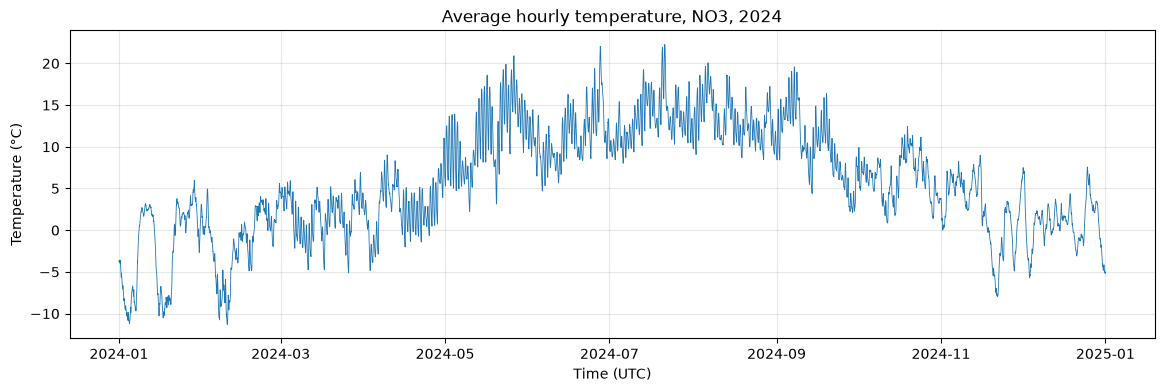

In [13]:
# Plot the average temperature in NO3 as a function of time
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(weather_no3.index, weather_no3['temperature_2m'], linewidth=0.6)
ax.set_title('Average hourly temperature, NO3, 2024')
ax.set_xlabel('Time (UTC)')
ax.set_ylabel('Temperature (°C)')
ax.grid(alpha=0.3)
plt.show()

In [14]:
from sklearn.neighbors import LocalOutlierFactor


def lof_anomalies(series, contamination=0.01, n_neighbors=20, time_step=0.01):
    """
    Find anomalies in a time series with the Local Outlier Factor (LOF) method.

    contamination : proportion of the observations marked as anomalies
    n_neighbors   : number of neighbours used to estimate the local density
    time_step     : distance between two consecutive hours on the scaled time axis
    Returns the plot, a summary and the anomalous values.
    """
    values = series.values

    # Two features: scaled time index and standardised values
    time_index = np.arange(len(values)) * time_step
    standardised = (values - values.mean()) / values.std()
    X = np.column_stack([time_index, standardised])

    # Fit LOF; observations labelled -1 are anomalies
    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
    is_anomaly = lof.fit_predict(X) == -1

    # Plot the series with the anomalies in red
    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(series.index, values, linewidth=0.6, label=series.name)
    ax.scatter(series.index[is_anomaly], values[is_anomaly], color='red', s=12, zorder=3,
               label='Anomalies (LOF)')
    ax.set_title(f'LOF anomalies in {series.name} ({contamination:.1%} of the hours)')
    ax.set_xlabel('Time (UTC)')
    ax.set_ylabel(series.name)
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right')

    # Summary of the anomalies
    anomalies = series[is_anomaly]
    summary = {
        'number of anomalies': len(anomalies),
        'share of anomalies (%)': round(100 * len(anomalies) / len(series), 2),
        'lowest anomaly': round(float(anomalies.min()), 2),
        'highest anomaly': round(float(anomalies.max()), 2),
    }
    return fig, summary, anomalies

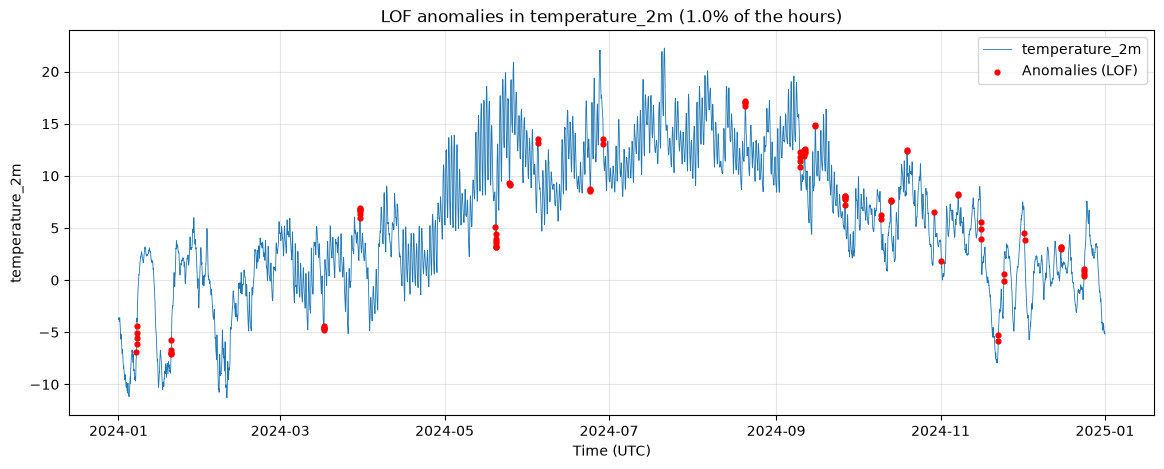

{'number of anomalies': 88, 'share of anomalies (%)': 1.0, 'lowest anomaly': -7.12, 'highest anomaly': 17.16}


time
1     10
3     11
5     11
6      7
8      4
9     18
10     8
11    10
12     9
Name: temperature_2m, dtype: int64

In [15]:
# Test the function on the temperature in NO3 with the default proportion of 1 %
fig, summary, anomalies = lof_anomalies(weather_no3['temperature_2m'])
plt.show()
print(summary)
anomalies.groupby(anomalies.index.month).size()     # number of anomalies per month

**Interpretation:** With the default proportion of 1 %, 88 hours are marked as anomalies. They are not the warmest or coldest hours of the year (the peaks around 22 °C in July and the lows around −11 °C in January/February are not marked), but hours where the temperature differs from the hours close in time, such as sudden drops or rises, e.g. late May and mid-September. This shows the difference from the SPC method: LOF looks for local deviations, not values that are extreme compared with the whole year.

## Seasonal-Trend decomposition using LOESS (STL)
The degree of filling (`fill_ratio`) for NO3 is downloaded from the Magasinstatistikk API (as in part 2) and decomposed into trend, seasonal and residual components with STL. The data is weekly, so the period is 52 weeks.

In [16]:
# Download the Magasinstatistikk data from NVE's API and prepare it as in part 2
import requests

r = requests.get("https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData")
reservoirs = pd.DataFrame(r.json()).rename(columns={
    'dato_Id': 'date', 'omrType': 'area_type', 'omrnr': 'area_number', 'fyllingsgrad': 'fill_ratio'})
reservoirs['date'] = pd.to_datetime(reservoirs['date'])
reservoirs['area'] = reservoirs['area_type'] + ' ' + reservoirs['area_number'].astype(str)

# Weekly degree of filling for NO3, sorted by date
fill_no3 = (reservoirs[reservoirs['area'] == 'EL 3']
            .sort_values('date')
            .set_index('date')['fill_ratio'])
print(fill_no3.shape)
fill_no3.head()

(1659,)


date
1995-01-08    0.602376
1995-01-15    0.569943
1995-01-22    0.542203
1995-01-29    0.508148
1995-02-05    0.473883
Name: fill_ratio, dtype: float64

In [17]:
from statsmodels.tsa.seasonal import STL


def stl_decomposition(series, period=52, seasonal=13, trend=105, robust=False):
    """
    Decompose a time series into trend, seasonal and residual components with STL.

    period   : number of observations in one season (52 weeks = one year)
    seasonal : length of the seasonal smoother (odd number; higher = more stable season)
    trend    : length of the trend smoother (odd number, larger than the period; higher = smoother trend)
    robust   : True gives less weight to outliers when fitting
    Returns the plot of the decomposition.
    """
    stl = STL(series, period=period, seasonal=seasonal, trend=trend, robust=robust)
    result = stl.fit()

    # Plot the original series and the three components
    fig = result.plot()
    fig.set_size_inches(12, 8)
    fig.suptitle(f'STL of {series.name} (seasonal={seasonal}, trend={trend}, robust={robust})', y=1.02)
    return fig

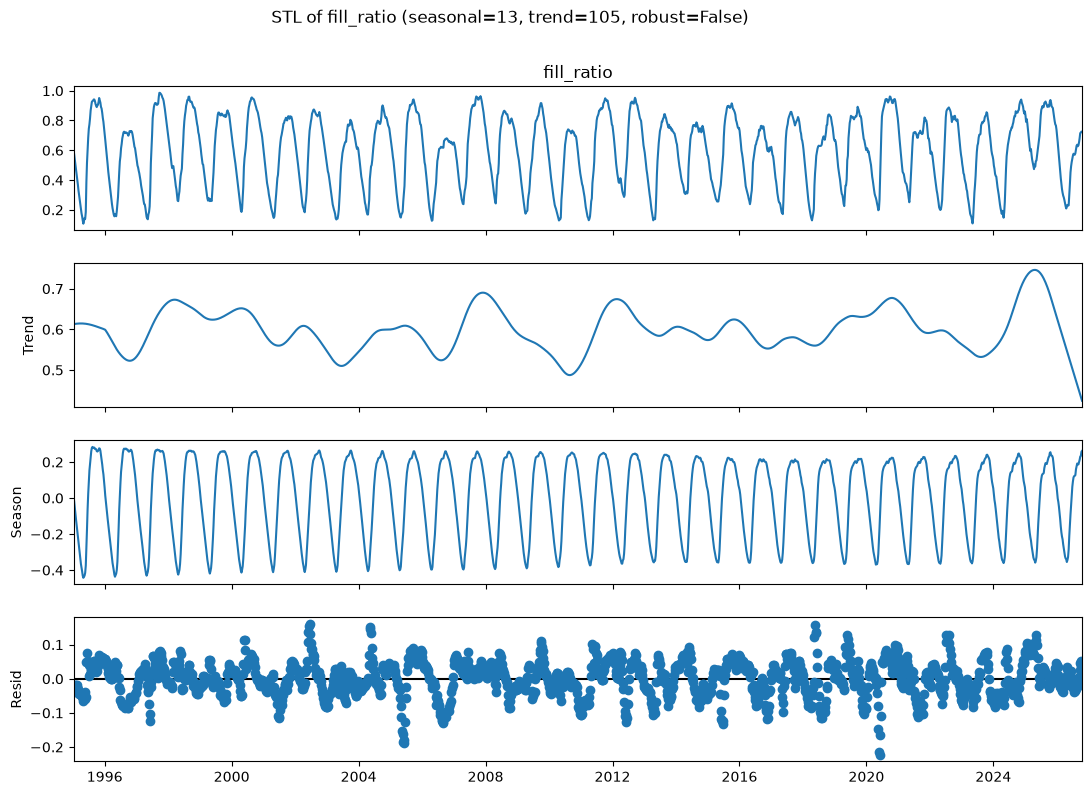

In [18]:
# Test the function on the degree of filling in NO3 with the default parameters
fig = stl_decomposition(fill_no3)
plt.show()

**Interpretation:** The seasonal component shows a stable yearly cycle of about ±0.3: reservoirs are drawn down in winter and filled during the snowmelt. The trend varies between about 0.5 and 0.75, with low periods around 1996, 2006 and 2010–2011 and a peak around 2025. The steep drop at the very end should be interpreted carefully, since the trend is less certain at the end of the series where the smoother only has data on one side. The residuals are mostly within ±0.1.

## Spectrogram
The spectrogram shows how the frequency content of the degree of filling changes over time. It is computed with the short-time Fourier transform (STFT): the series is split into overlapping windows, and the Fourier transform of each window gives one column in the plot. With weekly data the sampling rate is 52 per year, so the frequency axis is in cycles per year.

In [19]:
from scipy.signal import stft


def spectrogram(series, window_length=104, overlap=78, samples_per_year=52):
    """
    Plot a spectrogram of a time series using the short-time Fourier transform.

    window_length    : number of observations in each window (104 weeks = two years)
    overlap          : number of observations shared by two consecutive windows (must be < window_length)
    samples_per_year : sampling rate (52 for weekly data), gives the frequency in cycles per year
    Returns the plot.
    """
    # STFT; the mean of each window is removed so the constant level does not dominate
    f, t, Zxx = stft(series.values, fs=samples_per_year, nperseg=window_length,
                     noverlap=overlap, detrend='constant')

    # Time axis in years from the first date in the series
    start = series.index[0].year + series.index[0].dayofyear / 365

    fig, ax = plt.subplots(figsize=(12, 4))
    mesh = ax.pcolormesh(start + t, f, np.abs(Zxx), shading='gouraud')
    ax.set_ylim(0, 6)                                 # show the low frequencies, where the variation is
    ax.set_title(f'Spectrogram of {series.name} (window {window_length}, overlap {overlap})')
    ax.set_xlabel('Year')
    ax.set_ylabel('Frequency (cycles per year)')
    fig.colorbar(mesh, ax=ax, label='Amplitude')
    return fig

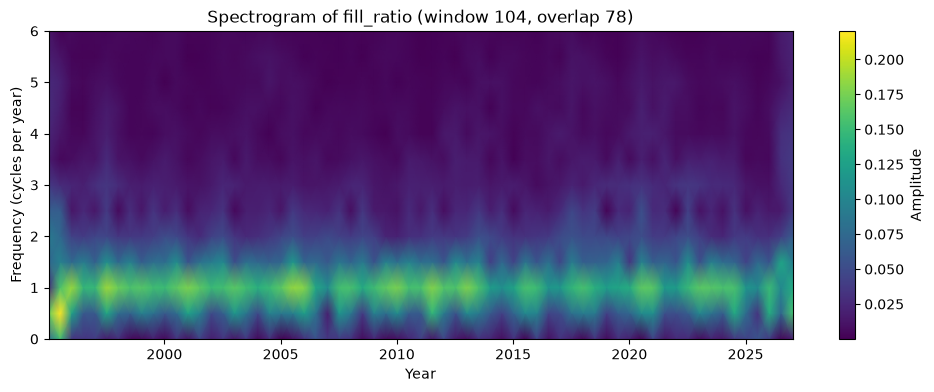

In [20]:
# Test the function on the degree of filling in NO3 with the default parameters
fig = spectrogram(fill_no3)
plt.show()

**Interpretation:** The strong band at 1 cycle per year throughout the period is the yearly cycle. The weaker band at about 2 cycles per year appears because the yearly cycle is not a pure sine wave: the filling in spring is fast, while the drawdown in winter is slower. The bright area at the very start (1995) is an edge effect, as the first window does not have data on both sides.